In [2]:
import time
import sys
import os

# Add the parent directory to sys.path
notebook_path = os.getcwd()  # Get the current working directory where the notebook is located
parent_directory = os.path.dirname(notebook_path)  # Move to the parent directory
sys.path.append(parent_directory)

# Now you can import config
from config import *
#from Minimal_Model_2D import *
import Minimal_Model_2D as mm2d
import time

np.set_printoptions(threshold=sys.maxsize)

In [2]:
### Plotting spin splitting while varying width ###

NSM = 60          # in nm
#MY = 2             # no of subbands
AX = 5             # lattice spacing in nm
DELTA = 0.165      # in meV
#MEFF_SC = 0.05     # Ge
#MEFF_SM = 0.05     # Proximitized Ge
MEFF_SC = 0.023     # InAs
MEFF_SM = 0.023     # InAs

NSC = 400

N = 2*NSC + NSM

PHI = 0.5*np.pi 

#print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)

ALPHAT = 400  #meV-nm # 20 is within perturbative regime for widths atleast up to 100 nm

#LY = np.linspace(20, 100, 51)

#M = np.arange(4, 20, 1, dtype=int )


LY = 20
AY = 5 

M = (LY//AY)*5

OMEGA = 2*4*hbm/LY**2/MEFF_SC

MU_SM = 0.8 + OMEGA/2        ## As per Andreev Aprroximation chemical pot >> superconducting gap 
MU_SC = 0.8 + OMEGA/2        ## constant potential over reference level across all widths

K_NUM = 8


print('lengths=', M*AY, LY)

print('subband energies=', OMEGA/2, 3*OMEGA/2)

print('4t=', 4*hbm/AX**2/MEFF_SM)

print('mu = ', MU_SM)


#Ep_cu = np.empty((M.shape[0],K_NUM) )
#Kappa = np.empty((LY.shape[0],1) )

#for i in range(M.shape[0]):

Fcu = mm2d.twoD_Minimal_Model(N, NSM, NSC, M, AX, AY ,OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)
#Kappa[i] = Fli.Ky_pr(1,2).real*ALPHAT/OMEGA[i]

Hcu = Fcu.H_sys(PHI, so = 'cu')

Ecu = eigsh(Hcu , k=K_NUM, sigma=0, return_eigenvectors=False)

Ecu = np.sort(Ecu)

print(Ecu/DELTA)

print((Ecu[K_NUM//2+1]-Ecu[K_NUM//2])/DELTA)


lengths= 100 20
subband energies= 16.579300334086994 49.73790100226098
4t= 265.2688053453919
mu =  17.379300334086995
[-1.04162356 -1.04115189 -0.48030403 -0.4783386   0.4783386   0.48030403
  1.04115189  1.04162356]
0.00032429672547479305


In [3]:
print((Ecu[K_NUM//2+1]-Ecu[K_NUM//2])/DELTA)

0.0019654346998472304


In [9]:
### Plotting spin splitting while varying width ###

NSM = 60          # in nm
#MY = 2             # no of subbands
AX = 5             # lattice spacing in nm
DELTA = 0.165      # in meV
#MEFF_SC = 0.05     # Ge
#MEFF_SM = 0.05     # Proximitized Ge
MEFF_SC = 0.023     # InAs
MEFF_SM = 0.023     # InAs
NSC = 500
N = 2*NSC + NSM
PHI = 0.5*np.pi 

#print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)

ALPHAT = 400  #meV-nm # 20 is within perturbative regime for widths atleast up to 100 nm

LY = np.linspace(20, 100, 21)

print(LY)

OMEGA = 2*4*hbm/LY**2/MEFF_SC

AY = 5

M = np.linspace(LY[0]//AY*5, LY[-1]//AY*5, LY.shape[0], dtype=int)                    

print(M)

MU_SM = 0.8 + OMEGA/2        ## As per Andreev Aprroximation chemical pot >> superconducting gap 
MU_SC = 0.8 + OMEGA/2        ## constant potential over reference level across all widths

K_NUM = 8

Ep_cu = np.empty((M.shape[0],K_NUM) )
#Kappa = np.empty((LY.shape[0],1) )

for i in range(M.shape[0]):

    Fcu = mm2d.twoD_Minimal_Model(N, NSM, NSC, M[i], AX, AY ,OMEGA[i], ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC[i], MU_SM[i])
    #Kappa[i] = Fli.Ky_pr(1,2).real*ALPHAT/OMEGA[i]
    
    Hcu = Fcu.H_sys(PHI, so = 'cu')
    
    Ecu = eigsh(Hcu , k=K_NUM, sigma=0, return_eigenvectors=False)
    
    Ecu = np.sort(Ecu)
    
    Ep_cu[i,:] = Ecu 
    
    if i%1==0:
        print(i)



[ 20.  24.  28.  32.  36.  40.  44.  48.  52.  56.  60.  64.  68.  72.
  76.  80.  84.  88.  92.  96. 100.]
[ 20  24  28  32  36  40  44  48  52  56  60  64  68  72  76  80  84  88
  92  96 100]
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20


In [10]:
np.save("2d_cubic_energy_vs_width.npy", Ep_cu)

In [10]:
Ep_cu = np.load("C:\\Users\\Vivrekar\\Desktop\\Spin_Splitting_Ge_ABS\\Figure_Codes\\2d_cubic_energy_vs_width.npy")

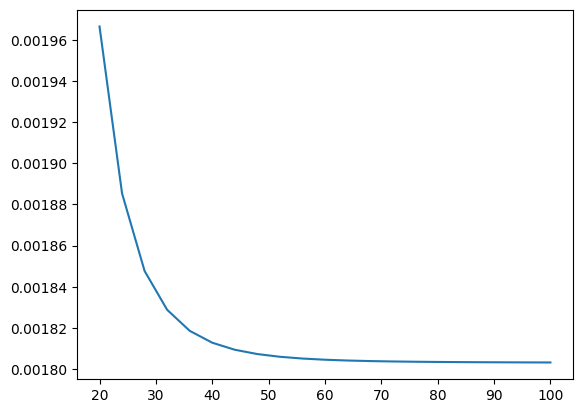

In [11]:
plt.plot(LY, (Ep_cu[:,K_NUM//2+1]-Ep_cu[:,K_NUM//2])/DELTA)

Text(0, 0.5, 'spin splitting(meV)')

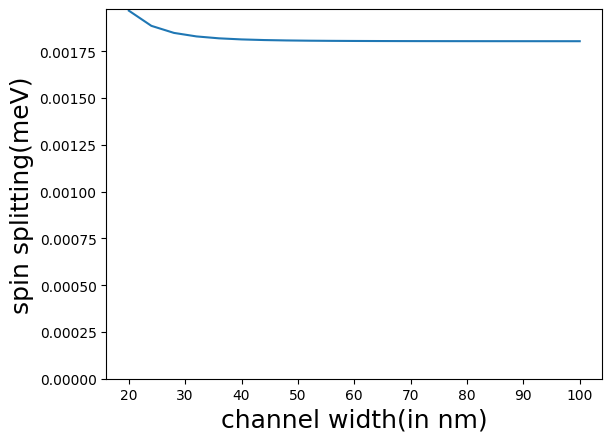

In [12]:
plt.plot(LY, (Ep_cu[:,K_NUM//2+1]-Ep_cu[:,K_NUM//2])/DELTA)
plt.ylim(ymin=0)
plt.xlabel(r"channel width(in nm)", fontsize=18)
plt.ylabel("spin splitting(meV)", fontsize=18)

In [3]:
### Plotting spin splitting while varying width ###

NSM = 60          # in nm
#MY = 2             # no of subbands
AX = 5             # lattice spacing in nm
DELTA = 0.165      # in meV
#MEFF_SC = 0.05     # Ge
#MEFF_SM = 0.05     # Proximitized Ge
MEFF_SC = 0.023     # InAs
MEFF_SM = 0.023     # InAs
NSC = 400
N = 2*NSC + NSM
PHI = 0.5*np.pi 

#print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)

ALPHAT = 20  #meV-nm # 20 is within perturbative regime for widths atleast up to 100 nm

LY = np.linspace(20, 100, 21)

print(LY)

OMEGA = 2*4*hbm/LY**2/MEFF_SC

AY = 5

M = np.linspace(LY[0]//AY*5, LY[-1]//AY*5, LY.shape[0], dtype=int)                    

print(M)

MU_SM = 0.8 + OMEGA/2        ## As per Andreev Aprroximation chemical pot >> superconducting gap 
MU_SC = 0.8 + OMEGA/2        ## constant potential over reference level across all widths

K_NUM = 4

Ep_cu = np.empty((M.shape[0],K_NUM) )
#Kappa = np.empty((LY.shape[0],1) )

for i in range(M.shape[0]):

    Fcu = mm2d.twoD_Minimal_Model(N, NSM, NSC, M[i], AX, AY ,OMEGA[i], ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC[i], MU_SM[i])
    #Kappa[i] = Fli.Ky_pr(1,2).real*ALPHAT/OMEGA[i]
    
    Hcu = Fcu.H_sys(PHI, so = 'li')
    
    Ecu = eigsh(Hcu , k=K_NUM, sigma=0, return_eigenvectors=False)
    
    Ecu = np.sort(Ecu)
    
    Ep_cu[i,:] = Ecu 
    
    if i%1==0:
        print(i)



[ 20.  24.  28.  32.  36.  40.  44.  48.  52.  56.  60.  64.  68.  72.
  76.  80.  84.  88.  92.  96. 100.]
[ 20  24  28  32  36  40  44  48  52  56  60  64  68  72  76  80  84  88
  92  96 100]
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20


In [8]:
np.save("2d_linear_energy_vs_width.npy", Ep_cu)

In [14]:
Ep_li = np.load("C:\\Users\\Vivrekar\\Desktop\\Spin_Splitting_Ge_ABS\\Figure_Codes\\2d_linear_energy_vs_width.npy")

Text(0, 0.5, 'spin splitting(meV)')

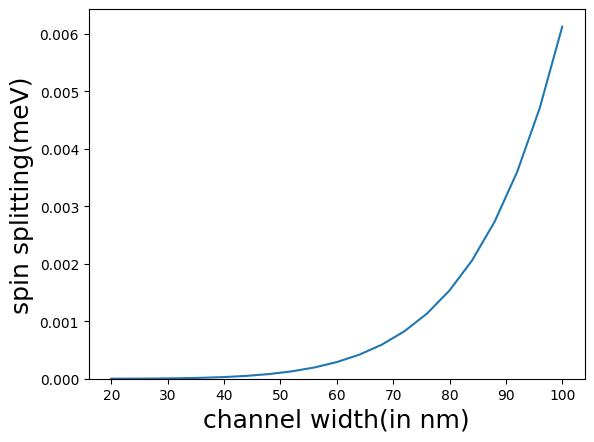

In [16]:
plt.plot(LY, (Ep_li[:,K_NUM//2+1]-Ep_li[:,K_NUM//2])/DELTA)
plt.ylim(ymin=0)
plt.xlabel(r"channel width(in nm)", fontsize=18)
plt.ylabel("spin splitting(meV)", fontsize=18)

In [26]:
print(Ep_cu)

[[-0.08035056 -0.08035046  0.08035046  0.08035056]
 [-0.07719244 -0.0771447   0.0771447   0.07719244]
 [-0.07694867 -0.07593804  0.07593804  0.07694867]]


In [27]:
K_NUM//2

2

In [28]:
K_NUM//2 + 1 

3

In [29]:
print(Ep_cu[:, K_NUM//2+1] - Ep_cu[:, K_NUM//2])

[9.83411372e-08 4.77316849e-05 1.01062904e-03]


In [5]:
### Plotting spin splitting while varying width ###

NSM = 60          # in nm
#MY = 2             # no of subbands
AX = 5             # lattice spacing in nm
DELTA = 0.165      # in meV
#MEFF_SC = 0.05     # Ge
#MEFF_SM = 0.05     # Proximitized Ge
MEFF_SC = 0.023     # InAs
MEFF_SM = 0.023     # InAs
NSC = 500
N = 2*NSC + NSM
PHI = 0.5*np.pi 

#print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)

ALPHAT = 20  #meV-nm # 20 is within perturbative regime for widths atleast up to 100 nm

LY = 100

print(LY)

OMEGA = 2*4*hbm/LY**2/MEFF_SC

AY = 5

M = 100                    

print(M*AX)

MU_SM = 0.8 + OMEGA/2        ## As per Andreev Aprroximation chemical pot >> superconducting gap 
MU_SC = 0.8 + OMEGA/2        ## constant potential over reference level across all widths

K_NUM = 4

#Ep_cu = np.empty((M.shape[0],K_NUM) )
#Kappa = np.empty((LY.shape[0],1) )

#for i in range(M.shape[0]):

Fcu = mm2d.twoD_Minimal_Model(N, NSM, NSC, M, AX, AY ,OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)
#Kappa[i] = Fli.Ky_pr(1,2).real*ALPHAT/OMEGA[i]

Hcu = Fcu.H_sys(PHI, so = 'li')

Ecu = eigsh(Hcu , k=K_NUM, sigma=0, return_eigenvectors=False)

Ecu = np.sort(Ecu)

print(Ecu)

print(Ecu[K_NUM//2+1]-Ecu[K_NUM//2])




100
500
[-0.07694789 -0.07593716  0.07593716  0.07694789]
0.0010107291315234884
